# Partie 2 : Systèmes RAG (Retrieval-Augmented Generation)


Ce notebook couvre :
1. État de l'art des systèmes RAG
2. Architecture et pipeline complet
3. Implémentation d'un système RAG simple
4. Démonstration et comparaison avec/sans RAG

---
## 1. État de l'art

### 1.1 Définition des systèmes RAG

Le **RAG (Retrieval-Augmented Generation)** est une architecture qui combine deux composants :
- Un **moteur de recherche** (retriever) qui récupère les documents pertinents depuis une base de connaissances
- Un **modèle génératif** (generator/LLM) qui produit une réponse en s'appuyant sur ces documents

Introduit par Lewis et al. (2020, Meta AI), le RAG permet d'enrichir les LLMs avec des connaissances externes sans les ré-entraîner.

### 1.2 Limites des LLMs sans RAG

| Problème | Description |
|---|---|
| **Knowledge cutoff** | Le modèle ignore les événements postérieurs à son entraînement |
| **Hallucinations** | Le modèle invente des faits plausibles mais faux |
| **Domaine spécifique** | Pas de connaissance des données internes d'une entreprise |
| **Coût de mise à jour** | Re-entraîner un LLM coûte des millions de dollars |

### 1.3 Comparaison des approches

| Approche | Avantages | Inconvénients |
|---|---|---|
| **Fine-tuning** | Adapte le modèle au domaine | Coûteux, données labelisées requises |
| **Prompt Engineering** | Simple, pas d'entraînement | Limité par la taille du contexte |
| **RAG** | Connaissances à jour, explicable | Pipeline plus complexe |

### 1.4 Variantes modernes
- **Naive RAG** : pipeline simple retrieve → generate
- **Advanced RAG** : re-ranking, query expansion, hybrid search
- **Modular RAG** : composants interchangeables (LlamaIndex, LangChain)
- **Self-RAG** : le modèle décide lui-même quand récupérer des documents

---
## 2. Architecture et Pipeline RAG

Le pipeline complet d'un système RAG comprend 6 étapes :

```
┌─────────────────────────────────────────────────────────────┐
│                    PHASE D'INDEXATION                       │
│                                                             │
│  Documents  →  Chunking  →  Embedding  →  Vector Store      │
└─────────────────────────────────────────────────────────────┘
                                                              
┌─────────────────────────────────────────────────────────────┐
│                    PHASE DE REQUÊTE                         │
│                                                             │
│  Question  →  Embedding  →  Recherche top-k  →  Prompt      │
│                                                    ↓        │
│                                              LLM → Réponse  │
└─────────────────────────────────────────────────────────────┘
```

**Étape 1** : Encodage des documents en embeddings (vecteurs denses)  
**Étape 2** : Indexation dans une base vectorielle (FAISS)  
**Étape 3** : Encodage de la requête utilisateur  
**Étape 4** : Recherche des top-k documents par similarité cosinus  
**Étape 5** : Construction du prompt augmenté (contexte + question)  
**Étape 6** : Génération de la réponse par le LLM  

---
## 3. Implémentation

### 3.0 Installation des dépendances

In [1]:
import subprocess, sys

pkgs = [
    "sentence-transformers",
    "faiss-cpu",
    "transformers",
    "torch",
    "numpy",
    "requests"
]

for pkg in pkgs:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", pkg])

print("✅ Installation terminée — redémarrez le kernel puis continuez")

✅ Installation terminée — redémarrez le kernel puis continuez


### 3.1 Imports

In [2]:
import numpy as np
import faiss
import textwrap
import warnings
warnings.filterwarnings('ignore')

from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch

print("✅ Imports réussis")

✅ Imports réussis


### 3.2 Corpus de documents

Notre base de connaissances porte sur les **Transformers et le NLP**. Dans un projet réel, ces documents viendraient de PDFs, d'articles ou d'une base de données.

In [ ]:
# ─────────────────────────────────────────────
# Corpus de 15 documents sur les Transformers
# ─────────────────────────────────────────────
corpus = [
    # --- Architecture Transformer ---
    "The Transformer architecture was introduced in 2017 in the paper 'Attention Is All You Need' "
    "by Vaswani et al. from Google Brain. It uses self-attention mechanisms instead of "
    "recurrent or convolutional layers, enabling parallelization during training.",

    "The self-attention mechanism allows each token in a sequence to attend to all other tokens. "
    "It computes queries, keys, and values from the input embeddings. "
    "The attention score between two tokens is computed as the dot product of their query and key vectors.",

    "The Transformer uses multi-head attention, which runs several attention mechanisms in parallel. "
    "Each head learns to attend to different aspects of the input. "
    "The outputs of all heads are concatenated and projected to the final representation.",

    "Positional encoding is added to token embeddings in the Transformer to give the model "
    "information about the position of each token in the sequence. "
    "Without positional encoding, the model would be permutation invariant.",

    # --- BERT ---
    "BERT (Bidirectional Encoder Representations from Transformers) was developed by Google in 2018. "
    "It is pre-trained using two tasks: Masked Language Modeling (MLM) and Next Sentence Prediction (NSP). "
    "BERT uses only the encoder part of the Transformer architecture.",

    "BERT is bidirectional, meaning it reads text in both left-to-right and right-to-left directions simultaneously. "
    "This allows BERT to capture context from both sides of a word. "
    "BERT-base has 12 layers, 12 attention heads, and 110 million parameters.",

    "Fine-tuning BERT involves adding a task-specific head on top of the pre-trained model. "
    "For text classification, a linear layer is added on top of the [CLS] token representation. "
    "BERT achieved state-of-the-art results on 11 NLP benchmarks when it was released.",

    # --- GPT ---
    "GPT (Generative Pre-trained Transformer) was developed by OpenAI. "
    "GPT-1 was released in 2018, GPT-2 in 2019, GPT-3 in 2020, and GPT-4 in 2023. "
    "GPT uses only the decoder part of the Transformer and is trained with causal language modeling.",

    "GPT-3 has 175 billion parameters and was trained on 570GB of text data. "
    "It demonstrated impressive few-shot learning capabilities. "
    "GPT models generate text autoregressively, predicting the next token given all previous tokens.",

    # --- HuggingFace ---
    "HuggingFace was founded in 2016 in New York. It provides the Transformers library, "
    "which offers thousands of pre-trained models for NLP, vision, and audio tasks. "
    "The library supports PyTorch, TensorFlow, and JAX backends.",

    "The HuggingFace Hub hosts over 300,000 pre-trained models and 50,000 datasets. "
    "Users can share and download models with a single line of code. "
    "The pipeline API provides a simple interface to run inference on pre-trained models.",

    # --- RAG ---
    "Retrieval-Augmented Generation (RAG) was introduced by Lewis et al. from Meta AI in 2020. "
    "RAG combines a dense retriever with a sequence-to-sequence generator. "
    "It retrieves relevant documents and conditions the generator on both the query and retrieved documents.",

    "RAG solves the knowledge cutoff problem of LLMs by accessing external knowledge bases at inference time. "
    "Unlike fine-tuning, RAG does not require re-training the model when new information is added. "
    "This makes RAG more flexible and cost-effective for knowledge-intensive tasks.",

    # --- Embeddings ---
    "Sentence embeddings represent an entire sentence as a single dense vector. "
    "The sentence-transformers library by Reimers and Gurevych provides models optimized for "
    "computing sentence embeddings. The all-MiniLM-L6-v2 model produces 384-dimensional embeddings.",

    # --- FAISS ---
    "FAISS (Facebook AI Similarity Search) is a library for efficient similarity search and clustering "
    "of dense vectors. It was developed by Meta AI Research. "
    "FAISS supports exact and approximate nearest neighbor search, "
    "scaling to billions of vectors on GPU."
]

print(f"Corpus chargé : {len(corpus)} documents")
print(f"\nExemple (doc 0) :")
print(textwrap.fill(corpus[0], width=80))

✅ Corpus chargé : 15 documents

Exemple (doc 0) :
The Transformer architecture was introduced in 2017 in the paper 'Attention Is
All You Need' by Vaswani et al. from Google Brain. It uses self-attention
mechanisms instead of recurrent or convolutional layers, enabling
parallelization during training.


### 3.3 Étape 1 & 2 — Encodage et Indexation (phase offline)

On encode tous les documents en vecteurs d'embeddings, puis on les indexe dans FAISS.

In [4]:
# ─────────────────────────────────────────────
# Chargement du modèle d'embeddings
# all-MiniLM-L6-v2 : rapide, léger, 384 dimensions
# ─────────────────────────────────────────────
print("⏳ Chargement du modèle d'embeddings...")
embedder = SentenceTransformer("all-MiniLM-L6-v2")
print("✅ Modèle chargé")

# ─────────────────────────────────────────────
# Étape 1 : Encodage des documents → embeddings
# ─────────────────────────────────────────────
print("\n⏳ Encodage du corpus...")
doc_embeddings = embedder.encode(
    corpus,
    convert_to_numpy=True,
    show_progress_bar=True
)

# Normalisation L2 (nécessaire pour la similarité cosinus avec FAISS)
faiss.normalize_L2(doc_embeddings)

print(f"\n✅ Embeddings calculés")
print(f"   Shape : {doc_embeddings.shape}  ({len(corpus)} docs × {doc_embeddings.shape[1]} dims)")

⏳ Chargement du modèle d'embeddings...


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1266.47it/s]


✅ Modèle chargé

⏳ Encodage du corpus...


Batches: 100%|██████████| 1/1 [00:00<00:00,  1.00it/s]


✅ Embeddings calculés
   Shape : (15, 384)  (15 docs × 384 dims)


In [5]:
# ─────────────────────────────────────────────
# Étape 2 : Indexation dans FAISS
# IndexFlatIP = Inner Product (= cosinus après normalisation L2)
# ─────────────────────────────────────────────
embedding_dim = doc_embeddings.shape[1]   # 384

index = faiss.IndexFlatIP(embedding_dim)
index.add(doc_embeddings)

print(f"✅ Index FAISS créé")
print(f"   Type    : IndexFlatIP (similarité cosinus exacte)")
print(f"   Vecteurs: {index.ntotal} documents indexés")
print(f"   Dimension: {embedding_dim}")

✅ Index FAISS créé
   Type    : IndexFlatIP (similarité cosinus exacte)
   Vecteurs: 15 documents indexés
   Dimension: 384


### 3.4 Étape 3 & 4 — Fonction de Retrieval

On encode la question et on recherche les **top-k documents** les plus similaires.

In [6]:
# ─────────────────────────────────────────────
# Fonction de retrieval : question → top-k docs
# ─────────────────────────────────────────────
def retrieve(question, k=3):
    """
    Encode la question et retourne les k documents
    les plus similaires du corpus.
    """
    # Étape 3 : Encodage de la requête
    query_embedding = embedder.encode(
        [question],
        convert_to_numpy=True
    )
    faiss.normalize_L2(query_embedding)

    # Étape 4 : Recherche top-k dans l'index FAISS
    scores, indices = index.search(query_embedding, k)

    resultats = []
    for score, idx in zip(scores[0], indices[0]):
        resultats.append({
            "document": corpus[idx],
            "score"   : float(score),
            "index"   : int(idx)
        })
    return resultats

# ── Test du retriever ──
question_test = "How does the attention mechanism work?"
docs_retrouves = retrieve(question_test, k=3)

print(f"❓ Question : {question_test}\n")
print("📚 Documents retrouvés :")
print("=" * 70)
for i, doc in enumerate(docs_retrouves):
    print(f"\n[Doc {i+1} | Score: {doc['score']:.4f} | Index corpus: {doc['index']}]")
    print(textwrap.fill(doc['document'], width=70))

❓ Question : How does the attention mechanism work?

📚 Documents retrouvés :

[Doc 1 | Score: 0.6371 | Index corpus: 1]
The self-attention mechanism allows each token in a sequence to attend
to all other tokens. It computes queries, keys, and values from the
input embeddings. The attention score between two tokens is computed
as the dot product of their query and key vectors.

[Doc 2 | Score: 0.5988 | Index corpus: 0]
The Transformer architecture was introduced in 2017 in the paper
'Attention Is All You Need' by Vaswani et al. from Google Brain. It
uses self-attention mechanisms instead of recurrent or convolutional
layers, enabling parallelization during training.

[Doc 3 | Score: 0.5471 | Index corpus: 2]
The Transformer uses multi-head attention, which runs several
attention mechanisms in parallel. Each head learns to attend to
different aspects of the input. The outputs of all heads are
concatenated and projected to the final representation.


### 3.5 Étape 5 & 6 — Génération augmentée (RAG)

On construit un **prompt augmenté** avec les documents récupérés, puis on génère la réponse avec un modèle seq2seq.

In [7]:
# ─────────────────────────────────────────────
# Chargement du modèle génératif
# FLAN-T5-base : léger, bon en Q&A et résumé
# ─────────────────────────────────────────────
print("⏳ Chargement du modèle génératif (FLAN-T5-base)...")
GEN_MODEL = "google/flan-t5-base"

gen_tokenizer = AutoTokenizer.from_pretrained(GEN_MODEL)
gen_model     = AutoModelForSeq2SeqLM.from_pretrained(GEN_MODEL)
gen_model.eval()

print("✅ Modèle génératif chargé")

⏳ Chargement du modèle génératif (FLAN-T5-base)...


Loading weights: 100%|██████████| 282/282 [00:00<00:00, 5716.96it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


✅ Modèle génératif chargé


In [8]:
# ─────────────────────────────────────────────
# Étape 5 : Construction du prompt augmenté
# ─────────────────────────────────────────────
def construire_prompt(question, documents):
    """
    Construit le prompt en concaténant le contexte récupéré
    et la question de l'utilisateur.
    """
    contexte = "\n".join(
        [f"- {doc['document']}" for doc in documents]
    )
    prompt = (
        f"Answer the question based on the context below.\n\n"
        f"Context:\n{contexte}\n\n"
        f"Question: {question}\n\n"
        f"Answer:"
    )
    return prompt

# ─────────────────────────────────────────────
# Étape 6 : Génération de la réponse
# ─────────────────────────────────────────────
def generer_reponse(prompt, max_new_tokens=150):
    """
    Génère une réponse à partir du prompt augmenté.
    """
    inputs = gen_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )
    with torch.no_grad():
        outputs = gen_model.generate(
            inputs["input_ids"],
            max_new_tokens=max_new_tokens,
            num_beams=4,
            early_stopping=True,
            no_repeat_ngram_size=3
        )
    return gen_tokenizer.decode(outputs[0], skip_special_tokens=True)


# ─────────────────────────────────────────────
# Pipeline RAG complet
# ─────────────────────────────────────────────
def rag(question, k=3, verbose=True):
    """
    Pipeline RAG complet :
    question → retrieve → prompt → generate → réponse
    """
    # Retrieval
    docs = retrieve(question, k=k)

    # Construction du prompt
    prompt = construire_prompt(question, docs)

    if verbose:
        print("📋 Prompt augmenté :")
        print("-" * 60)
        print(textwrap.fill(prompt, width=70))
        print("-" * 60)

    # Génération
    reponse = generer_reponse(prompt)
    return reponse, docs

print("✅ Pipeline RAG défini")

✅ Pipeline RAG défini


---
## 4. Démonstration et Expérimentation

### 4.1 Test du système RAG

In [9]:
# ─────────────────────────────────────────────
# Test avec plusieurs questions sur le corpus
# ─────────────────────────────────────────────
questions_demo = [
    "Who introduced the Transformer architecture and when?",
    "What is BERT and how was it pre-trained?",
    "What is FAISS and who developed it?",
    "What are the advantages of RAG over fine-tuning?"
]

for question in questions_demo:
    print("\n" + "=" * 70)
    print(f"❓ QUESTION : {question}")
    print("=" * 70)

    reponse, docs = rag(question, k=3, verbose=False)

    print(f"\n📚 Documents récupérés (top-3) :")
    for i, doc in enumerate(docs):
        print(f"  [{i+1}] Score {doc['score']:.3f} → {doc['document'][:80]}...")

    print(f"\n🤖 Réponse RAG :")
    print(textwrap.fill(reponse, width=70))


❓ QUESTION : Who introduced the Transformer architecture and when?

📚 Documents récupérés (top-3) :
  [1] Score 0.482 → GPT (Generative Pre-trained Transformer) was developed by OpenAI. GPT-1 was rele...
  [2] Score 0.452 → The Transformer architecture was introduced in 2017 in the paper 'Attention Is A...
  [3] Score 0.434 → The Transformer uses multi-head attention, which runs several attention mechanis...

🤖 Réponse RAG :
Vaswani et al

❓ QUESTION : What is BERT and how was it pre-trained?

📚 Documents récupérés (top-3) :
  [1] Score 0.622 → BERT (Bidirectional Encoder Representations from Transformers) was developed by ...
  [2] Score 0.595 → BERT is bidirectional, meaning it reads text in both left-to-right and right-to-...
  [3] Score 0.593 → Fine-tuning BERT involves adding a task-specific head on top of the pre-trained ...

🤖 Réponse RAG :
BERT (Bidirectional Encoder Representations from Transformers)

❓ QUESTION : What is FAISS and who developed it?

📚 Documents récupérés (to

### 4.2 Comparaison : Avec RAG vs Sans RAG

On compare les réponses générées **avec** et **sans** accès au corpus externe.

In [10]:
# ─────────────────────────────────────────────
# Génération SANS RAG (prompt direct, sans contexte)
# ─────────────────────────────────────────────
def sans_rag(question, max_new_tokens=150):
    """
    Répond directement sans récupération de documents.
    Le modèle ne dispose que de sa connaissance paramétrique.
    """
    prompt = f"Answer the following question:\n\nQuestion: {question}\n\nAnswer:"
    return generer_reponse(prompt, max_new_tokens)


# ─────────────────────────────────────────────
# Comparaison sur 3 questions
# ─────────────────────────────────────────────
questions_comparaison = [
    "How many parameters does BERT-base have?",
    "What library does HuggingFace provide for NLP?",
    "What is the dimension of embeddings from all-MiniLM-L6-v2?"
]

for question in questions_comparaison:
    print("\n" + "=" * 70)
    print(f"❓ {question}")
    print("=" * 70)

    # Sans RAG
    rep_sans = sans_rag(question)
    print(f"\n❌ Sans RAG :")
    print(f"   {rep_sans}")

    # Avec RAG
    rep_avec, docs = rag(question, k=2, verbose=False)
    print(f"\n✅ Avec RAG :")
    print(f"   {rep_avec}")
    print(f"   (basé sur {len(docs)} documents récupérés)")


❓ How many parameters does BERT-base have?

❌ Sans RAG :
   four

✅ Avec RAG :
   110 million
   (basé sur 2 documents récupérés)

❓ What library does HuggingFace provide for NLP?

❌ Sans RAG :
   NLP Library

✅ Avec RAG :
   Transformers
   (basé sur 2 documents récupérés)

❓ What is the dimension of embeddings from all-MiniLM-L6-v2?

❌ Sans RAG :
   4 x 4 mm

✅ Avec RAG :
   384
   (basé sur 2 documents récupérés)


### 4.3 Analyse de la similarité — Visualisation

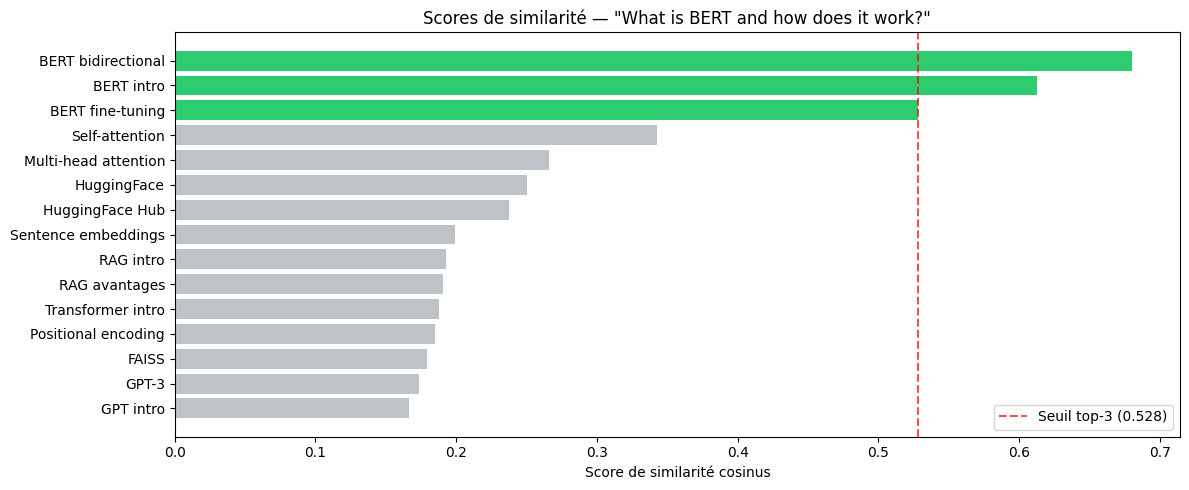

✅ Graphique sauvegardé : scores_similarite.png


In [11]:
# ─────────────────────────────────────────────
# Visualisation des scores de similarité
# ─────────────────────────────────────────────
import matplotlib.pyplot as plt

question_viz = "What is BERT and how does it work?"

# Récupération des scores pour TOUS les documents
query_emb = embedder.encode([question_viz], convert_to_numpy=True)
faiss.normalize_L2(query_emb)
scores_all, indices_all = index.search(query_emb, len(corpus))

# Labels courts pour l'affichage
labels = [
    "Transformer intro", "Self-attention", "Multi-head attention",
    "Positional encoding", "BERT intro", "BERT bidirectional",
    "BERT fine-tuning", "GPT intro", "GPT-3",
    "HuggingFace", "HuggingFace Hub", "RAG intro",
    "RAG avantages", "Sentence embeddings", "FAISS"
]

# Réordonner les labels selon l'ordre retourné par FAISS
labels_ordonnes = [labels[i] for i in indices_all[0]]
scores_ordonnes = scores_all[0]

# Couleurs : top-3 en vert, reste en gris
couleurs = ["#2ecc71" if i < 3 else "#bdc3c7" for i in range(len(scores_ordonnes))]

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.barh(labels_ordonnes, scores_ordonnes, color=couleurs)
ax.set_xlabel("Score de similarité cosinus")
ax.set_title(f'Scores de similarité — "{question_viz}"')
ax.axvline(x=scores_ordonnes[2], color='red', linestyle='--',
           alpha=0.7, label=f'Seuil top-3 ({scores_ordonnes[2]:.3f})')
ax.legend()
ax.invert_yaxis()
plt.tight_layout()
plt.savefig("scores_similarite.png", dpi=100, bbox_inches='tight')
plt.show()
print("✅ Graphique sauvegardé : scores_similarite.png")

### 4.4 Interface interactive simple

In [13]:
# ─────────────────────────────────────────────
# Chatbot RAG — démonstration avec questions fixes
# ─────────────────────────────────────────────
questions_demo_chat = [
    "What is the Transformer architecture?",
    "How does BERT differ from GPT?",
    "What is RAG and what problem does it solve?"
]

print("Chatbot RAG — Démonstration\n")

for question in questions_demo_chat:
    print(f"Vous : {question}")
    reponse, docs = rag(question, k=3, verbose=False)
    print(f"RAG  : {reponse}")
    print(f"   Sources : {', '.join([doc['document'][:40]+'...' for doc in docs])}")
    print()

Chatbot RAG — Démonstration

Vous : What is the Transformer architecture?
RAG  : multi-head attention
   Sources : The Transformer uses multi-head attentio..., The Transformer architecture was introdu..., Positional encoding is added to token em...

Vous : How does BERT differ from GPT?
RAG  : BERT uses only the encoder part of the Transformer architecture
   Sources : BERT is bidirectional, meaning it reads ..., BERT (Bidirectional Encoder Representati..., Fine-tuning BERT involves adding a task-...

Vous : What is RAG and what problem does it solve?
RAG  : knowledge cutoff
   Sources : RAG solves the knowledge cutoff problem ..., Retrieval-Augmented Generation (RAG) was..., The Transformer uses multi-head attentio...



---
## 5. Récapitulatif

### Composants du système RAG implémenté

| Composant | Outil utilisé | Rôle |
|---|---|---|
| **Corpus** | 15 documents texte | Base de connaissances |
| **Embeddings** | `all-MiniLM-L6-v2` (sentence-transformers) | Encodage vectoriel |
| **Index vectoriel** | FAISS `IndexFlatIP` | Recherche de similarité |
| **Modèle génératif** | `google/flan-t5-base` | Génération de réponses |

### Ce que le RAG apporte
- **Réponses ancrées** dans des faits vérifiables du corpus
- **Traçabilité** : on sait quels documents ont servi à générer la réponse
- **Mise à jour facile** : ajouter de nouveaux documents sans re-entraîner
- **Réduction des hallucinations** par rapport au LLM seul

### Améliorations possibles
- **Chunking intelligent** : découper les longs documents en paragraphes
- **Re-ranking** : utiliser un cross-encoder pour affiner le top-k
- **Hybrid search** : combiner recherche dense (FAISS) + sparse (BM25)
- **LLM plus puissant** : remplacer FLAN-T5 par un modèle via API (Mistral, GPT-4)
